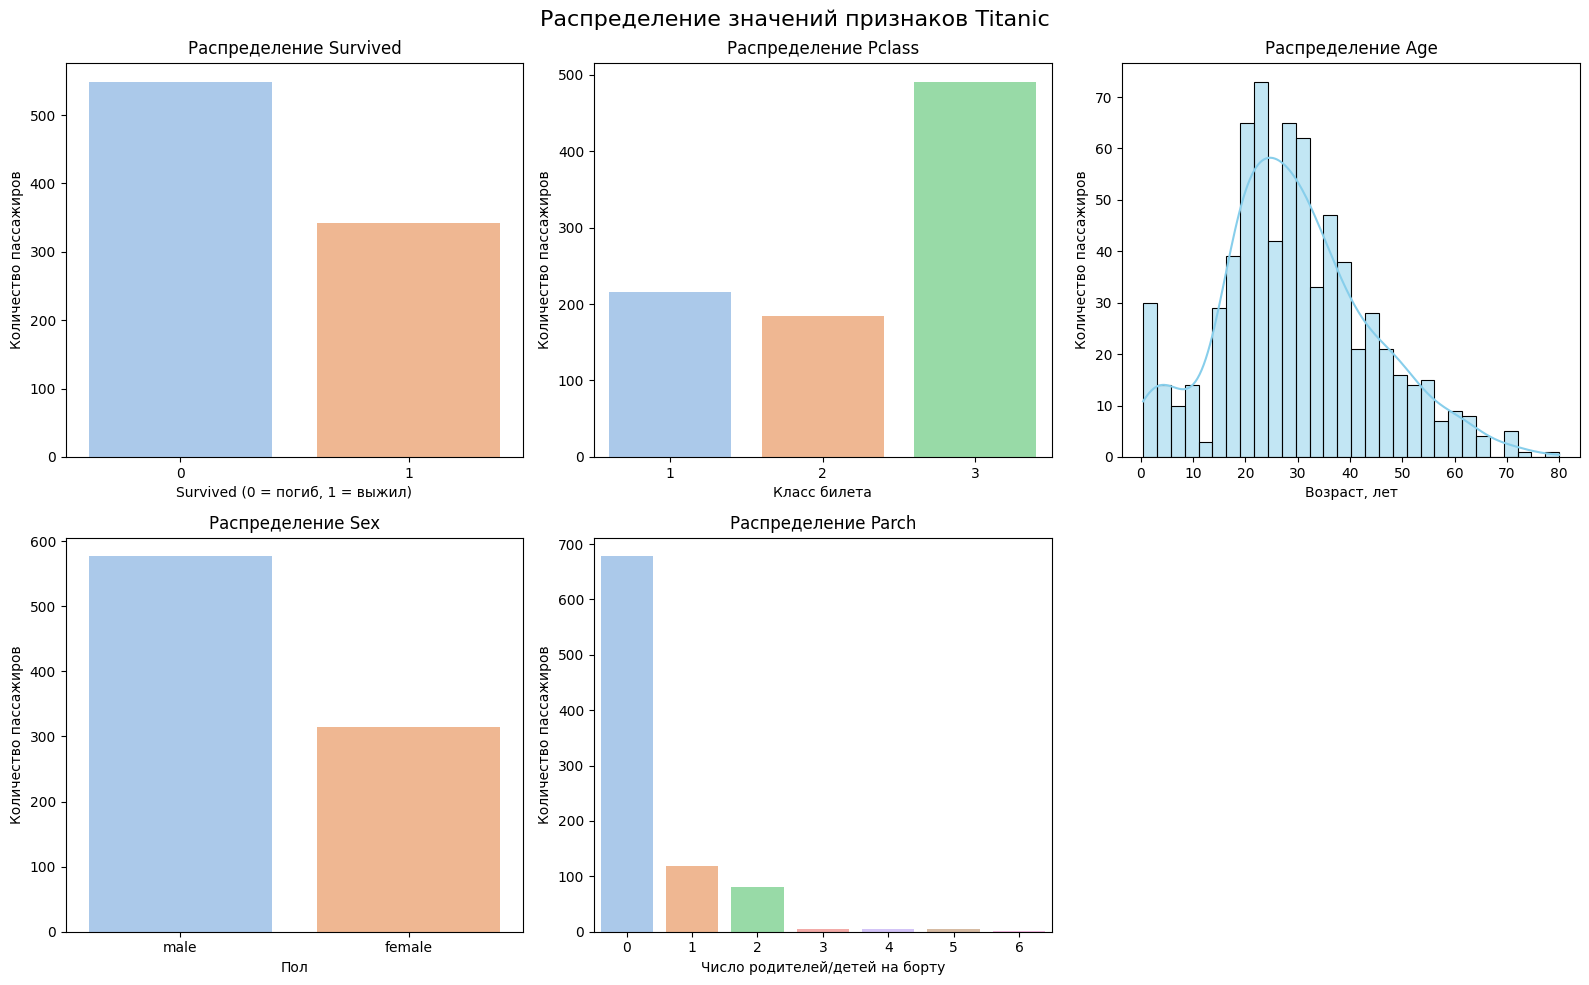

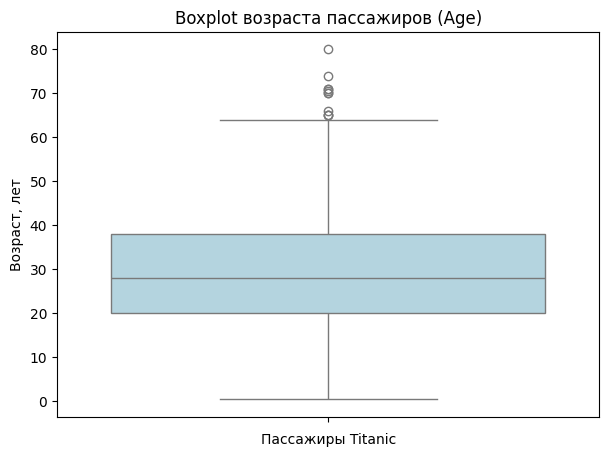

Интерпритация Графика
Возраст известен: 714
Минимум: 0.42
Максимум: 80.00
Q1 (25-й процентиль): 20.12
Медиана (Q2): 28.00
Q3 (75-й процентиль): 38.00
IQR: 17.88
Нижняя граница усов: -6.69
Верхняя граница усов: 64.81
Количество выбросов: 11
Возраст выбросов: от 65.00 до 80.00 лет
Средний возраст: 29.70
Стандартное отклонение: 14.53
Асимметрия: 0.39


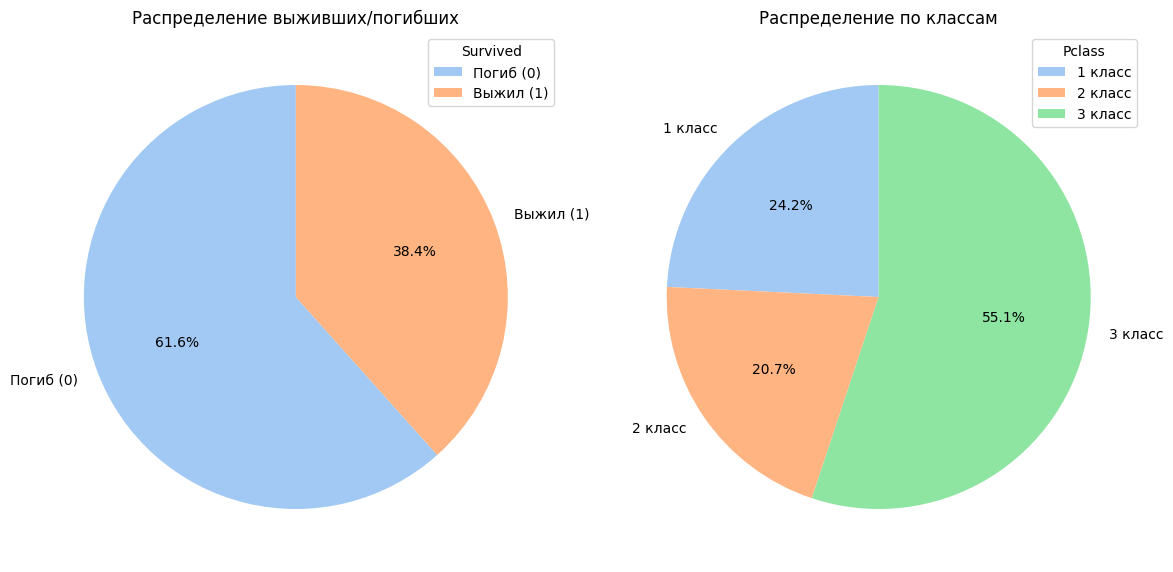

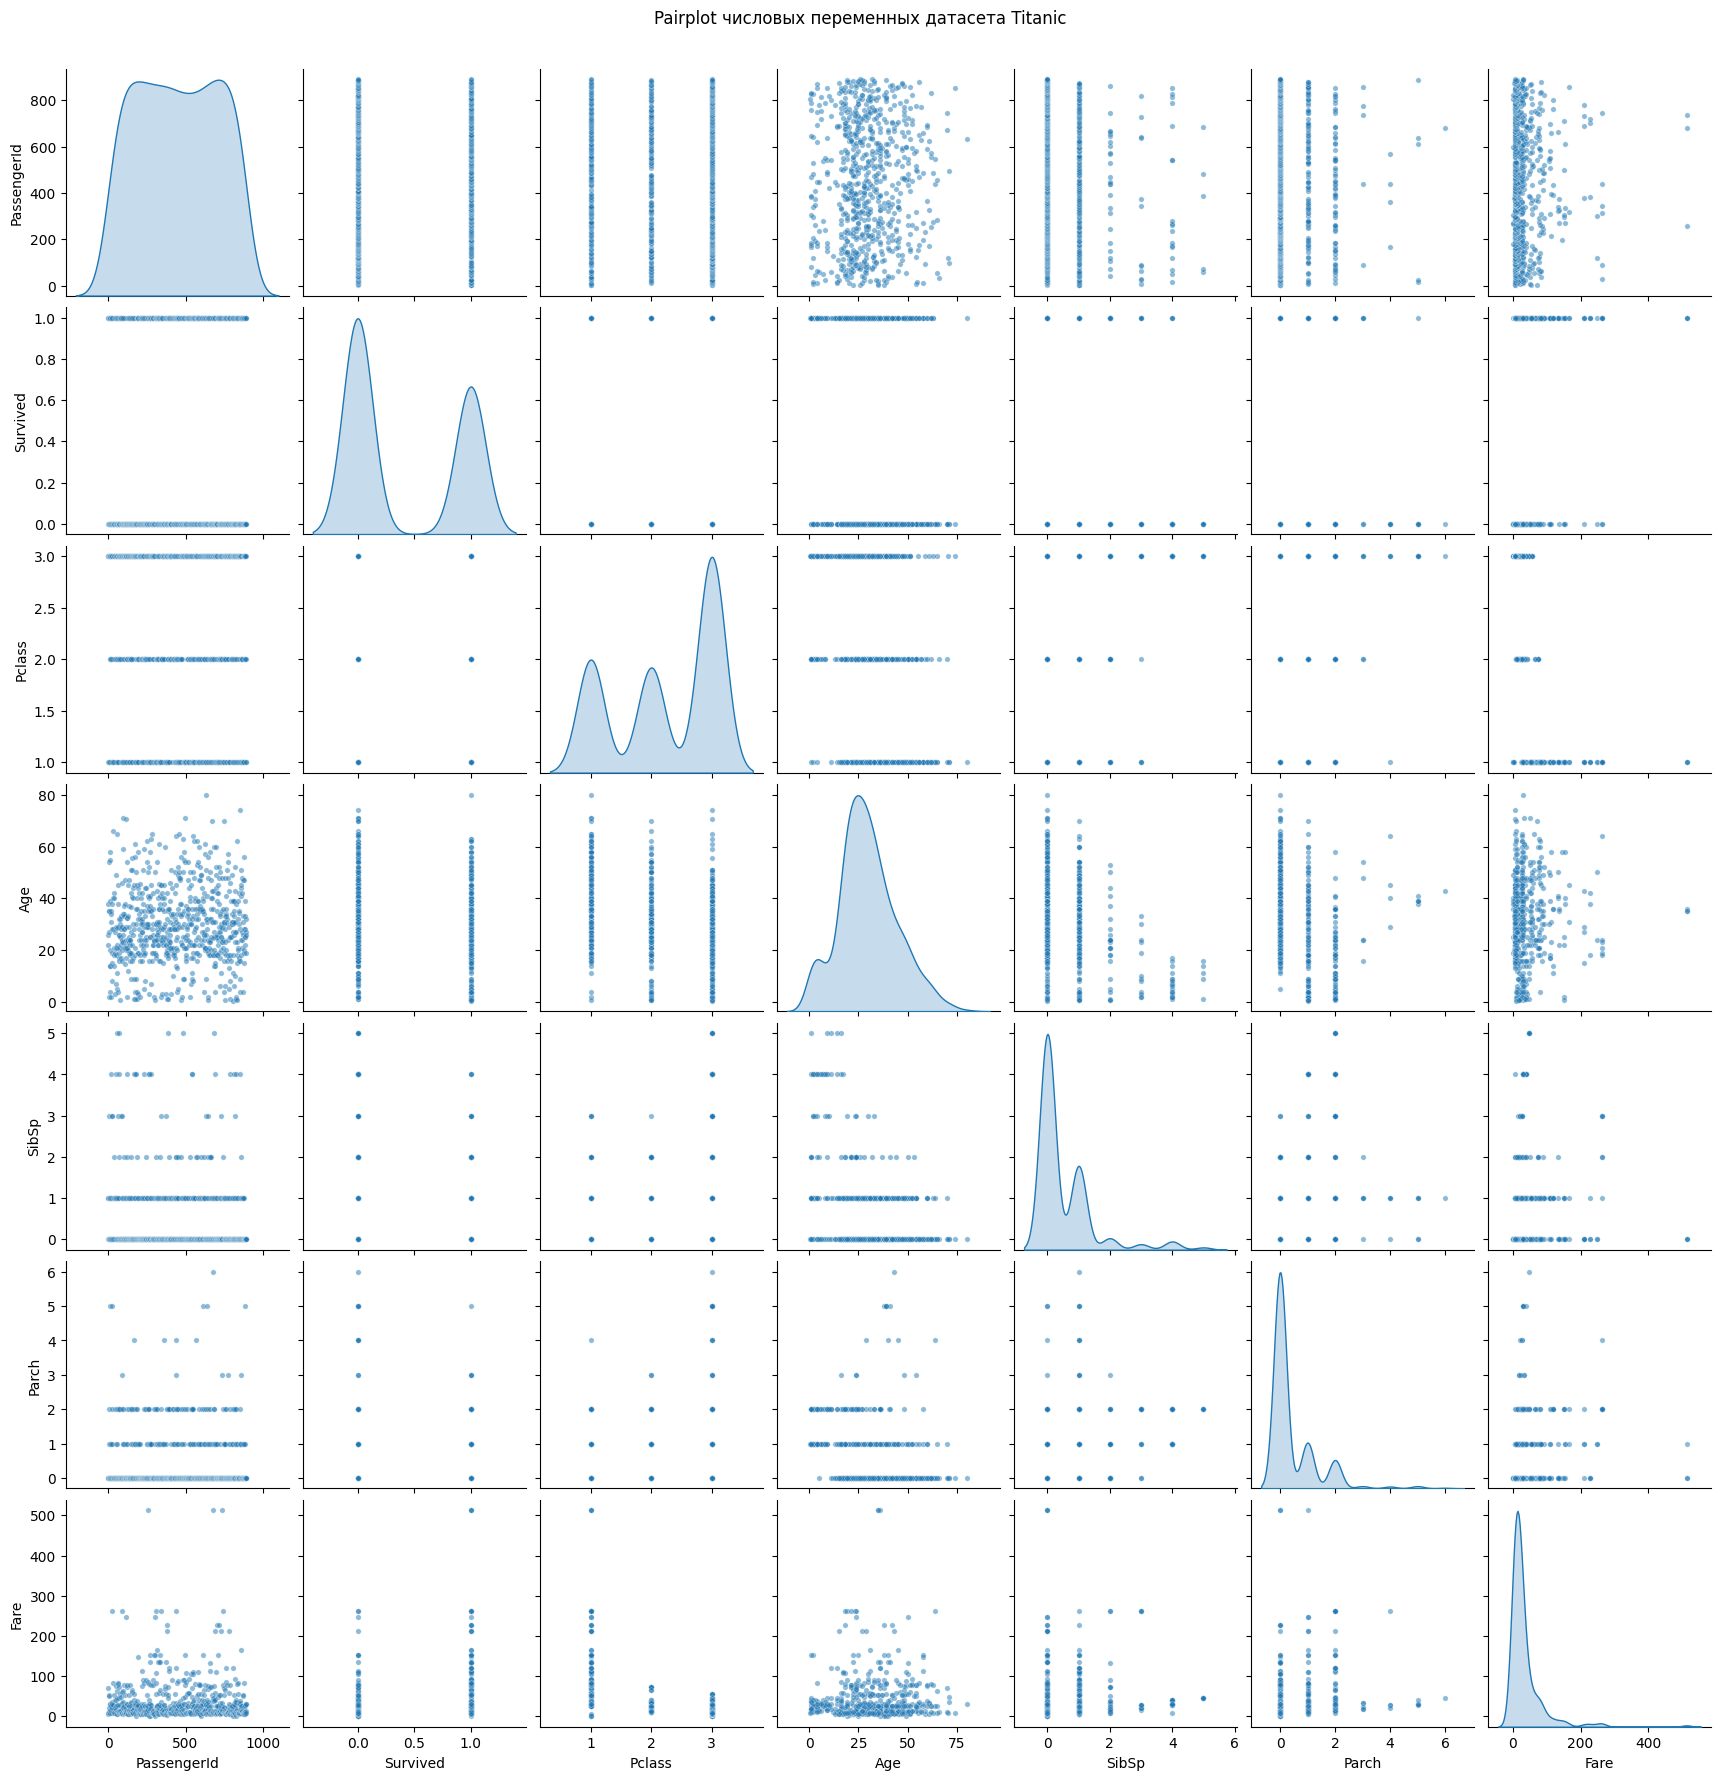

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

plt.rcParams['font.family'] = 'DejaVu Sans'
df = pd.read_csv('train.csv')
d = df[['Survived', 'Pclass', 'Age', 'Sex', 'Parch']]

# 1. Распределения
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Распределение значений признаков Titanic', fontsize=16)

sns.countplot(x='Survived', data=d, ax=axes[0, 0], hue='Survived',
              palette='pastel', legend=False)
axes[0, 0].set_title('Распределение Survived')
axes[0, 0].set_xlabel('Survived (0 = погиб, 1 = выжил)')
axes[0, 0].set_ylabel('Количество пассажиров')

sns.countplot(x='Pclass', data=d, ax=axes[0, 1], hue='Pclass',
              palette='pastel', legend=False)
axes[0, 1].set_title('Распределение Pclass')
axes[0, 1].set_xlabel('Класс билета')
axes[0, 1].set_ylabel('Количество пассажиров')

sns.histplot(d['Age'].dropna(), bins=30, kde=True,
             ax=axes[0, 2], color='skyblue')
axes[0, 2].set_title('Распределение Age')
axes[0, 2].set_xlabel('Возраст, лет')
axes[0, 2].set_ylabel('Количество пассажиров')

sns.countplot(x='Sex', data=d, ax=axes[1, 0], hue='Sex',
              palette='pastel', legend=False)
axes[1, 0].set_title('Распределение Sex')
axes[1, 0].set_xlabel('Пол')
axes[1, 0].set_ylabel('Количество пассажиров')

sns.countplot(x='Parch', data=d, ax=axes[1, 1], hue='Parch',
              palette='pastel', legend=False)
axes[1, 1].set_title('Распределение Parch')
axes[1, 1].set_xlabel('Число родителей/детей на борту')
axes[1, 1].set_ylabel('Количество пассажиров')

axes[1, 2].axis('off')
plt.tight_layout()
plt.show()

# 2. Boxplot Age
plt.figure(figsize=(7, 5))
sns.boxplot(y=d['Age'].dropna(), color='lightblue')
plt.title('Boxplot возраста пассажиров (Age)')
plt.ylabel('Возраст, лет')
plt.xlabel('Пассажиры Titanic')
plt.show()

# 2.2
age = df['Age'].dropna()

q1 = age.quantile(0.25)
q2 = age.median()
q3 = age.quantile(0.75)
iqr = q3 - q1

lower_whisker = q1 - 1.5 * iqr
upper_whisker = q3 + 1.5 * iqr

outliers = age[(age < lower_whisker) | (age > upper_whisker)]


text = "Интерпритация графика"
print("\033[1m" + text.title() + "\033[0m")

print(f'Возраст известен: {len(age)}')
print(f'Минимум: {age.min():.2f}')
print(f'Максимум: {age.max():.2f}')
print(f'Q1 (25-й процентиль): {q1:.2f}')
print(f'Медиана (Q2): {q2:.2f}')
print(f'Q3 (75-й процентиль): {q3:.2f}')
print(f'IQR: {iqr:.2f}')
print(f'Нижняя граница усов: {lower_whisker:.2f}')
print(f'Верхняя граница усов: {upper_whisker:.2f}')
print(f'Количество выбросов: {len(outliers)}')
print(f'Возраст выбросов: от {outliers.min():.2f} до {outliers.max():.2f} лет')
print(f'Средний возраст: {age.mean():.2f}')
print(f'Стандартное отклонение: {age.std():.2f}')
print(f'Асимметрия: {age.skew():.2f}')

# 3. Pie charts
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, col, labels, title in [
    (axes[0], 'Survived', ['Погиб (0)', 'Выжил (1)'], 'Распределение выживших/погибших'),
    (axes[1], 'Pclass', ['1 класс', '2 класс', '3 класс'], 'Распределение по классам')
]:
    counts = d[col].value_counts().sort_index()
    ax.pie(counts, labels=labels, autopct='%1.1f%%',
           startangle=90,
           colors=sns.color_palette('pastel', len(counts)))
    ax.set_title(title)
    ax.legend(labels, title=col, loc='best')

plt.tight_layout()
plt.show()

# 4. Pairplot
num_cols = ['PassengerId', 'Survived', 'Pclass',
            'Age', 'SibSp', 'Parch', 'Fare']

pp = sns.pairplot(df[num_cols].dropna(), diag_kind='kde',
                  plot_kws={'alpha': 0.5, 's': 15})
pp.fig.suptitle('Pairplot числовых переменных датасета Titanic', y=1.02)
plt.show()

# 5. Sunburst
sun = px.sunburst(
    df,
    path=['Pclass', 'Sex'],
    title='Иерархия пассажиров: класс билета → пол'
)
sun.update_traces(textinfo='label+value+percent parent')
sun.update_layout(title_x=0.5, font_size=14)
sun.show()